In [1]:
import matplotlib.pyplot as plt
from ZeroIntelligenceLOB import ZeroIntelligenceLOB as LOB
import math
import numpy as np
import json
import pandas as pd

In [2]:
# run capture_binance_depth.py first
# then run analyse_depth_data.py to get the parameters
# using binance because equity l2 is hard to come by

SYMBOL = "ethusdt"
with open(f"calibrated_params_{SYMBOL}.json") as f:
    params = json.load(f)

print(params)

np.random.seed(42)

lob = LOB(
    alpha=params["alpha"],
    mu=params["mu"],
    delta=params["delta"],
    sigma=params["sigma"],
    dp=params["dp"],
    snapshot=None,
    n_ticks=params["n_ticks"],
)

{'dp': 3.938046650013089e-06, 'mean_spread': 0.9482350971199413, 'alpha': 9.263374153666502, 'mu': 6.234706905901368, 'delta': 4.631687076833251, 'sigma': 0.0082, 'epsilon': 0.012183358288770053, 'n_ticks': 561}


In [3]:
n_events = 10000
record_every = 1
burn_in = 500

#for i in range(burn_in):
#    lob.next_event() # initialise the order book before we start recording - without this we get massive spreads at the start from an empty book

for i in range(n_events):
    lob.next_event()
    if i % record_every == 0:
        lob.record_state()

In [4]:
spreads = [s["spread"] for s in lob.history if not math.isnan(s["spread"])]

if lob.epsilon >= 0.1:
    epsilon_regime = "Large"
elif lob.epsilon >= 0.05:
    epsilon_regime = "Medium"
else:
    epsilon_regime = "Small"

print(f"Dimensionless epsilon: {lob.epsilon} ({epsilon_regime} regime)")
print(f"Mean spread: {sum(spreads) / len(spreads)}")
print(f"Final mid-price: {lob.history[-1]['mid_price']}")
print("Simulated seconds:", lob.clock)

Dimensionless epsilon: 0.012183358288770053 (Small regime)
Mean spread: 1.728360341699007e-05
Final mid-price: -0.0005696386069379681
Simulated seconds: 0.5831266224272561


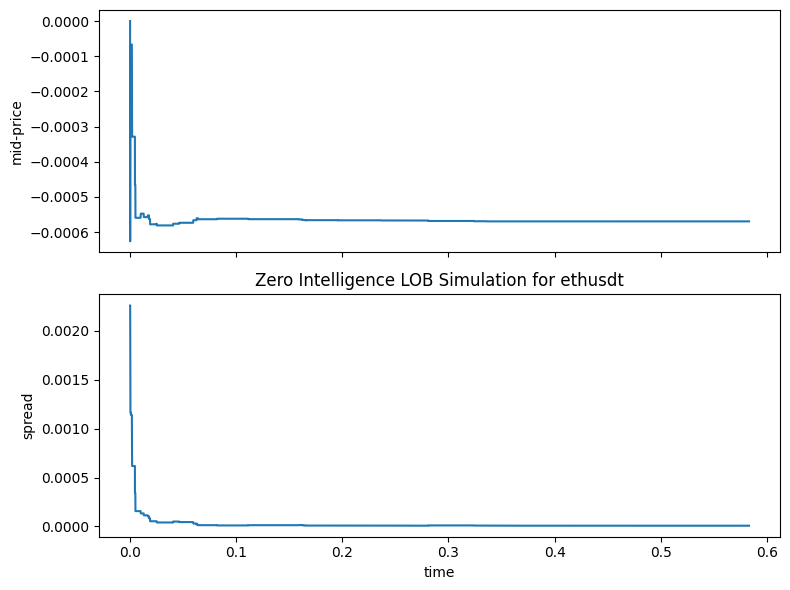

In [9]:
ignore = 0 # without burning in, hide the initial period where book is empty and spreads are large

mid = [s["mid_price"] for s in lob.history][ignore:]

spreads = np.array([s["spread"] for s in lob.history])[ignore:]
times   = np.array([s["time"]   for s in lob.history])[ignore:]
mask = ~np.isnan(spreads)


fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8,6))
plt.title(f"Zero Intelligence LOB Simulation for {SYMBOL}")
ax[0].plot(times, mid)
ax[0].set_ylabel("mid-price")
ax[1].plot(times[mask], spreads[mask])
ax[1].set_ylabel("spread")
ax[1].set_xlabel("time")
plt.tight_layout()
plt.show()

In [6]:
df = pd.read_pickle(f"binance_l2_{SYMBOL}.pkl")


price = (float(df.iloc[0]["bids"][0][0]) + float(df.iloc[0]["asks"][0][0]))/2

print("Start price:", price)
print("Final simulated price:",price * np.exp(mid[-1]))

Start price: 2539.325
Final simulated price: 2537.878914356646


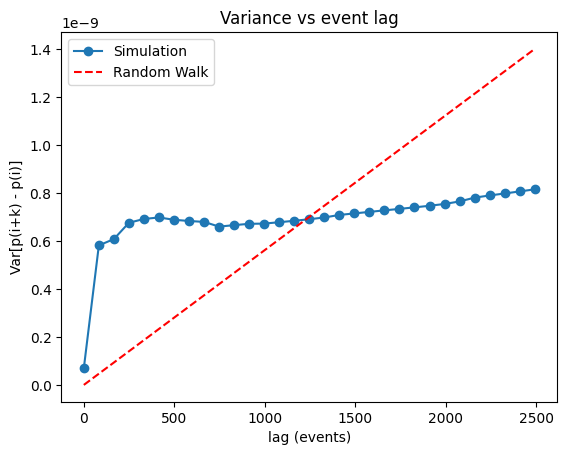

In [7]:
mid_array = np.array([s["mid_price"] for s in lob.history])
N         = len(mid_array)
max_k     = N // 4
ks        = np.arange(1, max_k, step=max_k//30)  # 30 points up to N/4
var_k     = np.zeros_like(ks, dtype=float)

for idx, k in enumerate(ks):
    deltas = mid_array[k:] - mid_array[:-k]
    var_k[idx] = np.var(deltas)

# 1. Jump size in log (dp), and market‐order rate in events/sec:
dp   = lob.dp                          # your tiny log‐tick
r_mkt = lob.mu / lob.sigma             # market orders per second

# 2. Total event rate
lambda_tot = (lob.alpha_total()        # limit orders/sec
             + r_mkt                   # market orders/sec
             + lob.delta_total())      # cancels/sec

# 3. Per‐event diffusion coefficient
D_event = (r_mkt * dp*dp) / lambda_tot

plt.plot(ks, var_k, marker='o', label='Simulation')
plt.plot(ks, D_event * ks, linestyle='--', color='red', label='Random Walk')
plt.xlabel("lag (events)")
plt.ylabel("Var[p(i+k) - p(i)]")
plt.title("Variance vs event lag")
plt.legend()
plt.show()
# This matches FIG 11 if record_every is low - mean reversion for small t then sublinear growth for large t